# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Pollux Gronier  Student ID: B00822392
2. Full name: Saty Viard Laroque  Student ID: B00822312
3. Full name: Fabrice Afopa  Student ID: B00817356
4. Full name: Eliott Beghin  Student ID: B00824999

**Project role (consultant / data scientist / risk analyst):** Data scientist
**Key quantity (one sentence, with unit):** Global operating nuclear capacity (GW, net), rebuilt year by year from the GEM Global Nuclear Power Tracker (Aug 2026); target = 2035, the horizon where the 40+ year fleet faces its life-extension (LTO) decisions.
**Repo URL:** https://github.com/Polluxgnr/lab5

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # project data below (GEM nuclear tracker)
DATA = Path("data/clean_nuclear_fleet.csv")   # output of src/data_processing.py in our project repo
REF_YEAR, TARGET = 2026, 2035                  # last observed year / decision horizon


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

> **Setup choices**
> - `REF_YEAR = 2026`: last year the tracker observes (GEM, Aug 2026). Anything later is projection.
> - `TARGET = 2035`: units built in the early-1980s boom (largest cohort of the fleet) hit 50 years between 2031 and 2035 → the LTO decisions our project prices land inside this window. Beyond ~2035 new reactors not yet started would matter, which we do not model.
> - One `rng` with `SEED = 42` for the whole notebook → every number below is reproducible on *Restart & Run All*.

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    fleet = pd.read_csv(DATA)
    # only units that actually produced power: construction/announced rows carry a *planned* start year
    # -> keeping them would leak future capacity into the history
    hist = fleet[fleet["Status"].isin(["operating", "retired"]) & fleet["Start_Year_Clean"].notna()]
    start, ret, cap = (hist[c].to_numpy() for c in ["Start_Year_Clean", "Retirement_Year_Clean", "Capacity_GW"])

    # 1990+: before that the series is the 1970s-80s build-out (+15 GW/yr), another regime
    years = np.arange(1990, REF_YEAR + 1)
    online = (start <= years[:, None]) & ~(ret <= years[:, None])   # NaN retirement -> still online
    series = pd.DataFrame({"year": years, "value": online.astype(float) @ cap})
    NAME, UNIT = "Global operating nuclear capacity", "GW"

    # sanity check vs the project pipeline (operating units today)
    print(f"{len(series)} years | 2026 rebuilt: {series.value.iloc[-1]:.1f} GW "
          f"| tracker 'operating' today: {fleet.loc[fleet.Clean_Status == 'operating', 'Capacity_GW'].sum():.1f} GW")
series.tail()

37 years | 2026 rebuilt: 407.8 GW | tracker 'operating' today: 407.8 GW


,year,value
32,2022,391.72
33,2023,394.46
34,2024,400.64
35,2025,401.56
36,2026,407.80


> **Why this quantity, built this way**
> - **Not LCOE or capex.** They are the project's outputs but have no yearly observed history → nothing to back-test. Operating GW is observed every year and is exactly what *LTO vs new build* changes: each GW not extended must be replaced by new capex at the IDC/WACC our model prices.
> - **Only `operating` + `retired` rows.** Construction/announced units carry a *planned* start year; keeping them would put 2027–2034 capacity into the "history" (look-ahead bias).
> - **From 1990.** 1970–1989 is the build-out (+15 GW/yr); a trend fitted across both regimes would be meaningless for today.
> - **Mothballed units dropped** (~20 GW): no retirement date in the tracker → cannot place them in time. Epistemic, listed in Q1.
> - **Check:** the rebuilt 2026 value equals the tracker's operating total (407.8 GW) → no unit lost or double-counted.

### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

- **What:** net GW of reactors connected to the grid, summed worldwide per year (408 GW in 2026). Physical exposure behind our value proposal.
- **Decision:** where capital goes first, *life extension (LTO) of the 40+ year fleet* vs *new builds*. If 2035 capacity hinges on licence decisions, LTO is the cheap hedge; if it hinges on build delays, new-build risk (IDC, WACC) dominates.
- **Uncertainty:**
  - **A**: construction lead time per project (median 7.2 y, p90 20 y post-2000); which individual units fail their safety review.
  - **E**: share of the 146 GW cohort that gets extended (no frequency to learn it from); data quality: GEM tags Japan's idled reactors as *operating*, start year ≠ commercial operation, 20 GW *mothballed* units dropped.
  - **S**: national policy (phase-out vs support), supply-chain shocks stretching every build.

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model="linear", level=0.90):
    """OLS trend + Student-t *prediction* interval (parameter + residual noise)."""
    y = train["value"].to_numpy(float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs value > 0")
        y = np.log(y)
    yr = train["year"].to_numpy(float)
    t_bar = yr.mean()                                    # centred year -> well-conditioned X'X
    X = np.column_stack([np.ones_like(yr), yr - t_bar])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    n, k = X.shape
    s2 = np.sum((y - X @ beta) ** 2) / (n - k)
    XtX_inv = np.linalg.inv(X.T @ X)

    fut = np.arange(train["year"].max() + 1, train["year"].max() + 1 + horizon)
    X0 = np.column_stack([np.ones(horizon), fut - t_bar])
    mean = X0 @ beta
    lev = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)      # x0'(X'X)^-1 x0, grows with distance
    half = stats.t.ppf(0.5 + level / 2, n - k) * np.sqrt(s2 * (1 + lev))
    lo, hi = mean - half, mean + half
    if model == "loglinear":                             # back-transform: exp(mean of log) = median
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)
    return pd.DataFrame({"year": fut, "mean": mean, "lo": lo, "hi": hi})


H = 5
train, test = series.iloc[:-H], series.iloc[-H:]
backtest = pd.concat([
    fit_predict(train, H, m).assign(model=m, actual=test["value"].to_numpy())
    for m in ["linear", "loglinear"]
])
backtest["inside"] = backtest["actual"].between(backtest["lo"], backtest["hi"])

# OLS assumes independent residuals; a capacity stock carries shocks forward (a closure stays closed)
yr_c = train["year"] - train["year"].mean()
resid = train["value"] - np.polyval(np.polyfit(yr_c, train["value"], 1), yr_c)
print(f"lag-1 autocorrelation of linear residuals: {resid.autocorr(1):.2f}  (0 = what the t-band assumes)")
backtest

lag-1 autocorrelation of linear residuals: 0.79  (0 = what the t-band assumes)


,year,mean,lo,hi,model,actual,inside
0,2022,395.16,384.42,405.90,linear,391.72,True
1,2023,396.59,385.79,407.39,linear,394.46,True
2,2024,398.03,387.16,408.89,linear,400.64,True
3,2025,399.46,388.53,410.39,linear,401.56,True
4,2026,400.89,389.90,411.89,linear,407.80,True
0,2022,395.81,384.31,407.65,loglinear,391.72,True
1,2023,397.35,385.75,409.30,loglinear,394.46,True
2,2024,398.90,387.18,410.96,loglinear,400.64,True
3,2025,400.45,388.62,412.64,loglinear,401.56,True
4,2026,402.01,390.06,414.32,loglinear,407.80,True


> **Method choices (B1)**
> - **Prediction, not confidence, interval.** A CI covers the *trend line*; next year's value also carries residual noise → `s²(1 + leverage)`. Using a CI here is how a "95% band" ends up covering 6%.
> - **Student-t with n−2 df.** σ is estimated from 32 points, not known → fatter tails than Normal.
> - **Leverage** grows with distance from the mean year → bands widen with horizon, as they should.
> - **Log model:** `exp(mean of log)` is the *median*, not the mean; the band is asymmetric (wider upward).
> - **5-year hold-out:** longest test we can afford while keeping 32 training years; still shorter than our 9-year horizon → a pass here is necessary, not sufficient.
> - **Residual autocorrelation** printed above: a capacity *stock* keeps shocks (a closed reactor stays closed). Positive autocorrelation → the iid band is too narrow at long horizons → B2 checks it.

### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

In [4]:
# (a) hits per model
print(backtest.groupby("model")["inside"].sum().rename("hits / 5").to_string(), "\n")

# (b) P(X >= k) misses if the band really is 90%: X ~ Bin(5, 0.1)
pd.DataFrame({"k misses": range(6), "P(X>=k)": stats.binom.sf(np.arange(6) - 1, 5, 0.1)})

model
linear       5
loglinear    5 



,k misses,P(X>=k)
0,0,1.00
1,1,0.41
2,2,0.08
3,3,0.01
4,4,0.00
5,5,0.00


**Your answer (Q2):**

**(a)** Linear **5/5**, log-linear **5/5** inside the 90% band.

**(b)** X ~ Bin(5, 0.1): P(X≥1)=0.41, **P(X≥2)=0.08**, P(X≥3)=0.01 → 2 misses already suspicious (<10%), 3 = reject. Flip side: 0 misses has P=1, so a 5-point pass proves little. Rolling back-test (B2) is harsher: h=1 coverage **78% (21/27)**, P(X≤21 | Bin(27, 0.9)) ≈ 0.05 → the band is **too narrow**, and windows overlap so the true evidence is even weaker than that p-value suggests. Why: residual lag-1 autocorrelation = **0.79** (the t-band assumes 0) → shocks persist (Germany 2011, 2023 closures), so errors pile up faster than an iid band widens.

**(c)** Keep **linear**: same coverage, simpler, symmetric in GW. Log ≈ linear because the series moves within ±10% (340–410 GW), so the gap is ~0 → model choice is *not* where the uncertainty sits; it sits in discrete policy breaks no trend can see. Hence Part F uses the simulation, not the trend: 2027–35 is when the 1980s build-out hits 50–60 years, a regime the past never saw.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# rolling origin: fit on years [0, c), predict c+1..c+3; first cutoff = 10th year
rows = []
for c in range(10, len(series)):
    tr = series.iloc[:c]
    for m in ["linear", "loglinear"]:
        p = fit_predict(tr, 3, m).assign(model=m, h=[1, 2, 3])
        p = p.merge(series, on="year")                   # drops horizons past 2026
        rows.append(p)
roll = pd.concat(rows)
roll["inside"] = roll["value"].between(roll["lo"], roll["hi"])
cov = roll.pivot_table(index="h", columns="model", values="inside", aggfunc=["mean", "count"])
cov

mean            count          
model linear loglinear linear loglinear
h                                      
1       0.78      0.78     27        27
2       0.73      0.73     26        26
3       0.72      0.72     25        25

> **Reading B2**
> - 27/26/25 forecast origins instead of 5 points → coverage is actually measurable.
> - Coverage falls with horizon (1 → 3 years) because the iid t-band ignores autocorrelation: errors accumulate, the band does not grow fast enough.
> - Caveat: overlapping windows share data → test points are **not independent**, so binomial p-values are optimistic. Still, the direction is clear: trend bands are too narrow → not used in Part F.

---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
YEARS = np.arange(REF_YEAR, TARGET + 1)
op = fleet[fleet["Clean_Status"] == "operating"].copy()
base_gw = op["Capacity_GW"].sum()                        # today's fleet (= 2026 of `series`)

# --- known retirements: retirement year already announced in the tracker (policy, not uncertain here)
planned = op[op["Retirement_Year_Clean"].between(REF_YEAR + 1, TARGET)]

# --- LTO cohort: units hitting a 10-year licence/safety-review step at age 50 or 60 in 2027-2035
#     (US 40+20+20 licences, French "visites décennales"); a non-extended unit retires that year
age_now = REF_YEAR - op["Start_Year_Clean"]
rest = op.drop(planned.index)
step = np.where((REF_YEAR - rest["Start_Year_Clean"]).between(41, 49), 50,
                np.where((REF_YEAR - rest["Start_Year_Clean"]).between(51, 59), 60, 0))
cohort = rest[step > 0].assign(decision_year=lambda d: d["Start_Year_Clean"] + step[step > 0])

# --- construction pipeline: completion = construction start + lead time
build = fleet[fleet["Clean_Status"] == "construction"].copy()
build["cs"] = build["Const_Start_Year"].fillna(REF_YEAR)
modern_L = op.loc[op["COD_Year"] >= 2000, "Construction_Lead_Time_Years"].dropna().to_numpy()

print(f"fleet today {base_gw:.0f} GW | planned retirements {planned.Capacity_GW.sum():.1f} GW | "
      f"LTO cohort {cohort.Capacity_GW.sum():.1f} GW ({len(cohort)} units) | "
      f"under construction {build.Capacity_GW.sum():.1f} GW ({len(build)} units)")
print(f"lead time (COD >= 2000, n={len(modern_L)}): median {np.median(modern_L):.1f} y, "
      f"p90 {np.percentile(modern_L, 90):.1f} y")


# INPUT 1  p = share of the cohort that gets extended. Epistemic (+ S): a policy/regulatory unknown,
#   no frequency to estimate it from. Beta(8, 2): mean 0.8, 90% ~[0.55, 0.96]; most units get extended
#   (US: ~all units renewed to 60) but phase-outs exist (DE, BE, ES, TW) -> long left tail.
def draw_p(n, a=8, b=2):
    return rng.beta(a, b, n)


# INPUT 2  completion year of each unit under construction. Aleatoric per project:
#   bootstrap of post-2000 lead times, *conditional on the unit still being unfinished today*
#   (a site started in 2017 cannot finish in 6 years any more). `mult` stretches lead times (scenario).
def draw_completion(n, mult=1.0, cs_all=None, gen=None):
    cs_all = build["cs"] if cs_all is None else cs_all     # Part E swaps in LLM-extracted start years
    gen = rng if gen is None else gen
    out = np.empty((n, len(build)))
    for j, cs in enumerate(cs_all):
        elapsed = REF_YEAR - cs
        pool = modern_L[modern_L * mult > elapsed] * mult
        pool = pool if len(pool) else np.array([elapsed + 1.0])   # older than any record: +1 y
        out[:, j] = cs + gen.choice(pool, n)
    return np.maximum(np.ceil(out), REF_YEAR + 1)              # not online in 2026 by definition


# unit-level coin flips: given p, *which* units get extended is still random (lumpy 1 GW units)
U = rng.random((N, len(cohort)))


def compute_quantity(p, completion, u=U):
    """Operating GW per year (N x len(YEARS)) = fleet today - retirements + new grid connections."""
    yrs = YEARS[None, None, :]
    retire = u < (1 - np.asarray(p))[:, None]                                       # not extended
    lost_lto = ((cohort["decision_year"].to_numpy()[None, :, None] <= yrs) & retire[:, :, None])
    lost_lto = np.einsum("nuy,u->ny", lost_lto, cohort["Capacity_GW"].to_numpy())
    lost_plan = (planned["Retirement_Year_Clean"].to_numpy()[:, None] <= YEARS) .T @ planned["Capacity_GW"].to_numpy()
    new = np.einsum("nuy,u->ny", completion[:, :, None] <= yrs, build["Capacity_GW"].to_numpy())
    return base_gw - lost_lto - lost_plan[None, :] + new


def summarise(paths):
    x = paths[:, -1]                                     # target year
    q5, q50, q95 = np.percentile(x, [5, 50, 95])
    return {"median": q50, "lo90": q5, "hi90": q95, "width90": q95 - q5, "rel_halfwidth": (q95 - q5) / 2 / q50}


p_draw, comp_draw = draw_p(N), draw_completion(N)
paths = compute_quantity(p_draw, comp_draw)

# one-at-a-time: fix one input at its median, keep the other random
p_fix = np.full(N, np.median(p_draw))
comp_fix = np.broadcast_to(np.median(comp_draw, axis=0), comp_draw.shape)
# Monte Carlo noise check: same model, independent generator (global rng untouched)
g2 = np.random.default_rng(SEED + 1)
alt = summarise(compute_quantity(g2.beta(8, 2, N), draw_completion(N, gen=g2), u=g2.random(U.shape)))
base = summarise(paths)
print("MC check (seed 43 - seed 42), GW: " + ", ".join(f"{k} {alt[k] - base[k]:+.1f}" for k in ["lo90", "median", "hi90"]))

sens = pd.DataFrame({
    "both random": summarise(paths),
    "p fixed (LTO share)": summarise(compute_quantity(p_fix, comp_draw)),
    "lead times fixed": summarise(compute_quantity(p_draw, comp_fix)),
}).T
sens

fleet today 408 GW | planned retirements 12.1 GW | LTO cohort 146.1 GW (163 units) | under construction 90.9 GW (85 units)
lead time (COD >= 2000, n=133): median 7.2 y, p90 20.0 y


MC check (seed 43 - seed 42), GW: lo90 +0.2, median -0.1, hi90 +0.1


,median,lo90,hi90,width90,rel_halfwidth
both random,435.10,395.85,457.50,61.65,0.07
p fixed (LTO share),435.19,424.59,445.69,21.11,0.02
lead times fixed,454.55,416.07,475.11,59.05,0.06


> **Model and input choices (C)**
>
> `GW(year) = fleet today − announced retirements − non-extended LTO units + newly completed units`
>
> - **Why these two inputs.** They are the two physical channels of the project question: (1) does the old fleet stay (LTO), (2) how fast does new build arrive (delays → IDC). Everything else (announced retirements, current fleet) is known from the tracker.
> - **Input 1, LTO share `p` ~ Beta(8, 2).** A share in [0, 1] → Beta is the natural family. Mean 0.8: most licences get renewed (US: almost all units renewed to 60 years; France: 4th ten-year reviews granted), but whole countries have phased out (Germany, Belgium, Spain, Taiwan) → long left tail. **Epistemic**: one policy outcome, not a repeated coin.
> - **Unit coin flips `U`.** Given `p`, *which* units retire is still random, and units are lumpy (~1 GW) → keeps **aleatoric** spread that fixing `p` cannot remove.
> - **Decision ages 50 and 60.** Licences and safety reviews come in 10-year steps (US 40+20+20, French *visites décennales*). Units 41–49 today face the 50-year step, 51–59 the 60-year step, before 2035. Units already past 60 and still running are already extended → kept.
> - **Input 2, lead time = bootstrap of post-2000 builds (n = 133).** Empirical, no shape imposed: right-skewed (median 7.2 y, p90 20 y), which a Normal would miss. Post-2000 only: 1970s US/Soviet build times are a different industry.
> - **Conditioned on "not finished yet".** A unit started in 2017 cannot finish in 6 years any more → resample only lead times longer than time already elapsed. Without this, old stalled sites (Angra 3, Mochovce 4) would "finish" instantly.
> - **N = 5,000.** Monte Carlo error on the 5th/95th percentile is well below 1 GW (checked by changing the seed); smaller than any difference we interpret.
> - **One-at-a-time sensitivity.** Fixing an input at its median removes its spread; the shrink of the 90% width ranks inputs. Limitation: ignores interactions (Sobol indices would capture them).
> - **Not modelled:** reactors starting construction after 2026 (Chinese builds of ~5–6 years could still finish by 2035 → our 2035 is biased **low**), uprates, Japanese restarts.

### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

**(a)** 2035, baseline: **median 435 GW, 90% interval [396, 458] GW** (width 62 GW, ±7%).

**(b)** Fixing the **LTO share p** cuts the width 62 → **21 GW (−66%)**; fixing lead times only 62 → 59 GW (−4%). p is **epistemic** (regulatory/political, not a repeatable coin). Nuance: fixing lead times at their median *shifts* the median to 455 GW: lead times are right-skewed, so per-unit medians remove the long-delay tail → median of a sum ≠ sum of medians.

**(c)** Collect unit-level licence status of the 163-unit / 146 GW cohort (NRC renewals, ASN 4th/5th ten-year reviews, national LTO plans) → p becomes nearly known unit by unit. What stays: aleatoric construction delays and which reviews fail (~21 GW of width) whatever we collect.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [7]:
# each scenario = a change to the Part C inputs (same unit coin flips U -> differences are scenario only)
SCEN = {
    "Baseline":                    dict(a=8,  b=2, mult=1.0),
    "LTO-supportive (EU/US push)": dict(a=19, b=1, mult=1.0),   # mean 0.95: every regulator says yes
    "Restrictive licensing":       dict(a=3,  b=3, mult=1.0),   # mean 0.5: phase-out politics spread
    "Delays worsen (+50% build)":  dict(a=8,  b=2, mult=1.5),   # FOAK/supply chain, Flamanville/Hinkley-type
}
scen_paths = {k: compute_quantity(draw_p(N, v["a"], v["b"]), draw_completion(N, v["mult"])) for k, v in SCEN.items()}
scen = pd.DataFrame({k: summarise(v) for k, v in scen_paths.items()}).T
scen["gap_vs_baseline"] = scen["median"] - scen.loc["Baseline", "median"]
print(f"largest median gap: {scen['median'].max() - scen['median'].min():.1f} GW | "
      f"baseline 90% width: {scen.loc['Baseline', 'width90']:.1f} GW")
scen

largest median gap: 66.8 GW | baseline 90% width: 60.0 GW


,median,lo90,hi90,width90,rel_halfwidth,gap_vs_baseline
Baseline,434.82,397.16,457.14,59.98,0.07,0.00
LTO-supportive (EU/US push),455.38,437.81,465.13,27.32,0.03,20.55
Restrictive licensing,388.61,340.71,436.08,95.37,0.12,-46.21
Delays worsen (+50% build),419.73,380.97,441.80,60.83,0.07,-15.09


> **Scenario design (D)**
> - Each scenario changes **one** input of Part C → any gap is attributable to that lever.
> - **Supportive** Beta(19, 1): mean 0.95, narrow → regulators everywhere say yes (EU taxonomy, US subsequent renewals).
> - **Restrictive** Beta(3, 3): mean 0.5 *and* wider → phase-out politics spreading, with more disagreement about where it lands.
> - **Delays +50%**: lead times × 1.5 → Hinkley Point C, Flamanville 3, Vogtle 3–4 all ran ~1.5–2× their initial schedule.
> - **Same unit coin flips `U` in every scenario** (common random numbers) → gaps between medians are scenario effects, not Monte Carlo noise.

### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

- Largest gap between medians: **LTO-supportive 455 vs restrictive 389 GW = 67 GW**.
- Width within baseline: **60 GW** (90%). Gap > width; restrictive alone is 95 GW wide.
- Delays +50%: only −15 GW vs baseline; restrictive licensing −46 GW → policy on old units moves 2035 three times more than build delays.
- **Presentation:** one band per scenario. A single fan would blend a *choice* (licensing policy, which the client can track and lobby) with *noise* (build delays), and hide that the restrictive band barely overlaps the supportive one.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

> **How to run Part E**
> 1. Create a key at https://openrouter.ai/keys (add a few dollars of credit, or pick a `:free` model).
> 2. Before launching Jupyter, set it in the terminal: `setx OPENROUTER_API_KEY "sk-or-..."` (Windows, then reopen the terminal) or `export OPENROUTER_API_KEY=sk-or-...` (macOS/Linux). Never paste the key in the notebook: it would be pushed to GitHub.
> 3. `pip install openai pydantic` (OpenRouter uses the OpenAI client).
> 4. Choose `MODEL` below, run Part E once. Raw answers are saved to `data/e_llm_raw.csv` → later runs (and the grader) score the same answers without a key. `RERUN = True` to query again.
>
> **Design choices (E)**
> - **Variable:** per-unit **construction start year** (feeds `cs`, input 2 of Part C) + **expected operation year**. Both appear in news text before databases have them.
> - **Text:** English Wikipedia, 5 plants under construction (16 units), frozen by revision id in `data/e_excerpts.csv` → reproducible. A keyword + year filter keeps milestone paragraphs (crude retrieval: a date filtered out cannot be found).
> - **Gold = our hand labels** (`data/e_gold_hand.csv`, 16 units × 2 fields = 32 cases), read from the *same* excerpts with the *same* rules as the prompt → we score reading, not the source. `null` is a valid label when the text gives no date. Three ambiguous cases are flagged in the `note` column (Hinkley C1: site start 2017 vs first nuclear concrete 2018; Kudankulam 5: 2020 pour vs official 2021 start; Rooppur 1: licence only).
> - **GEM as a second check (E2):** comparing our labels with the tracker shows how much "error" comes from the text itself before any LLM is involved.
> - **Scoring:** exact year; null = null is correct. Errors split into *missed*, *invented* and *wrong year*, because they bias Part C in different directions.

In [8]:
import os, re
from typing import List, Optional
from pydantic import BaseModel, ValidationError

# --- E0. Text, prompt, model --------------------------------------------------------------------
# Variable: per-unit construction start year (feeds `cs`, input 2 of Part C) + expected operation year.
EX = pd.read_csv("data/e_excerpts.csv")                        # 5 Wikipedia articles, frozen revision ids
GOLD = pd.read_csv("data/e_gold_hand.csv", dtype={"unit": str})  # our hand labels, read from the same excerpts
RAW_CACHE = Path("data/e_llm_raw.csv")                         # raw answers saved by the live run

PROMPT = """You extract nuclear construction milestones from a text about one power plant.
Return ONLY a JSON object: {{"plant": str, "units": [{{"unit": str, "construction_start_year": int|null,
"expected_operation_year": int|null}}]}} with one entry per reactor unit that is still under construction.
construction_start_year: year of first safety-related (nuclear island) concrete for THAT unit.
expected_operation_year: latest stated year THAT unit is expected to start operating / be commissioned.
Use null when the text does not state the value for that unit. Never infer one unit's date from another's.

Text:
{text}
"""

MODEL = "openai/gpt-4o-mini"   # any OpenRouter model id, e.g. "meta-llama/llama-3.3-70b-instruct"
RERUN = False                  # True = call the API again even if a cache exists


def ask_llm(prompt, temperature=0.0):
    from openai import OpenAI                      # OpenRouter speaks the OpenAI API
    client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.environ["OPENROUTER_API_KEY"])
    r = client.chat.completions.create(model=MODEL, temperature=temperature,
                                       messages=[{"role": "user", "content": prompt}])
    return r.choices[0].message.content


# temperature 0 = greedy: we measure the instrument's default answer, not its sampling noise
if RAW_CACHE.exists() and not RERUN:
    RAW = pd.read_csv(RAW_CACHE)
elif os.environ.get("OPENROUTER_API_KEY"):
    RAW = pd.DataFrame({"id": EX["id"], "model": MODEL,
                        "raw": [ask_llm(PROMPT.format(text=t)) for t in EX["text"]]})
    RAW.to_csv(RAW_CACHE, index=False)             # freeze: later runs score the same answers
else:
    RAW = None
    print("No OPENROUTER_API_KEY and no cached answers -> extraction skipped (see instructions above).")


# --- E1. Schema + parser (Lab 4 pattern) --------------------------------------------------------
class UnitDates(BaseModel):
    unit: str
    construction_start_year: Optional[int] = None
    expected_operation_year: Optional[int] = None


class PlantExtraction(BaseModel):
    plant: str
    units: List[UnitDates]


def parse_response(raw):
    m = re.search(r"\{.*\}", raw, flags=re.S)        # tolerate text / code fences around the JSON
    if not m:
        return None, "no JSON object"
    try:
        return PlantExtraction.model_validate_json(m.group(0)), None
    except ValidationError as e:
        return None, f"schema: {e.errors()[0]['msg']}"


def unit_key(s):
    return re.sub(r"\D", "", str(s))                 # "Unit C1" / "1" / "C1" -> "1"


FIELDS = ["construction_start_year", "expected_operation_year"]
gold_long = GOLD.assign(unit_key=GOLD["unit"].map(unit_key)).melt(
    id_vars=["id", "plant", "unit", "unit_key"], value_vars=FIELDS, var_name="field", value_name="gold")

# --- E2. Before scoring the LLM: how far is the text itself from the tracker? ---------------------
gem = (fleet[fleet["Project Name"].isin(EX["gem_project"]) & (fleet["Clean_Status"] == "construction")]
       .assign(unit_key=lambda d: d["Unit Name"].map(unit_key))
       .merge(EX[["id", "gem_project"]], left_on="Project Name", right_on="gem_project")
       .rename(columns={"Const_Start_Year": "construction_start_year", "Start Year": "expected_operation_year"})
       .melt(id_vars=["id", "unit_key"], value_vars=FIELDS, var_name="field", value_name="gem"))
src = gold_long.merge(gem, on=["id", "unit_key", "field"])
src["agree"] = (src["gold"].astype("Int64") == src["gem"].astype("Int64")).fillna(False).astype(bool)
print("text (hand labels) vs GEM tracker, agreement by field:")
print(src.groupby("field")["agree"].agg(["sum", "count"]).to_string(), "\n")

# --- E3. Score the LLM against our hand labels --------------------------------------------------
if RAW is not None:
    rows, failures = [], []
    for _, r in RAW.iterrows():
        rec, err = parse_response(r["raw"])
        if rec is None:
            failures.append((r["id"], err))
            continue
        rows += [{"id": r["id"], "unit_key": unit_key(u.unit), **u.model_dump(exclude={"unit"})} for u in rec.units]
    llm = pd.DataFrame(rows, columns=["id", "unit_key", *FIELDS])
    print(f"model {RAW['model'].iloc[0]} | parsed {len(RAW) - len(failures)}/{len(RAW)} | failures: {failures}")

    pred_long = llm.melt(id_vars=["id", "unit_key"], value_vars=FIELDS, var_name="field", value_name="pred")
    # left join on the gold: a unit the model skipped or a failed parse counts as wrong
    sc = gold_long.merge(pred_long, on=["id", "unit_key", "field"], how="left")
    sc[["gold", "pred"]] = sc[["gold", "pred"]].astype("Int64")
    sc["correct"] = ((sc["pred"] == sc["gold"]) | (sc["pred"].isna() & sc["gold"].isna())).fillna(False).astype(bool)

    def error_type(r):
        if r["correct"]:
            return "correct"
        if pd.isna(r["pred"]):
            return "missed (date in text, null returned)"
        if pd.isna(r["gold"]):
            return "invented (no date in text)"
        return "wrong year"

    sc["error_type"] = sc.apply(error_type, axis=1)

    def beta90(k, n):                                # Beta(1,1) prior -> Beta(1+k, 1+n-k) posterior
        return stats.beta(1 + k, 1 + n - k).ppf([0.05, 0.95])

    acc = []
    for name, g in [("all fields", sc), *sc.groupby("field")]:
        k, n = int(g["correct"].sum()), len(g)
        lo, hi = beta90(k, n)
        acc.append({"subset": name, "k": k, "n": n, "accuracy": k / n, "lo90": lo, "hi90": hi})
    display(pd.DataFrame(acc).set_index("subset"))
    display(pd.crosstab(sc["error_type"], sc["field"], margins=True))
    display(sc.loc[~sc["correct"], ["plant", "unit", "field", "pred", "gold"]])

No OPENROUTER_API_KEY and no cached answers -> extraction skipped (see instructions above).


text (hand labels) vs GEM tracker, agreement by field:
                         sum  count
field                              
construction_start_year   10     16
expected_operation_year    5     16 



In [9]:
# --- E4. Does it matter for the key quantity? Swap GEM start years for LLM ones, rerun the baseline.
# null -> REF_YEAR, exactly what the Part C pipeline does with a missing start year.
if RAW is not None:
    cs_llm = build["cs"].copy()
    key = build.assign(unit_key=build["Unit Name"].map(unit_key)).reset_index()
    m = (key.merge(EX[["id", "gem_project"]], left_on="Project Name", right_on="gem_project")
            .merge(llm, on=["id", "unit_key"]))
    cs_llm.loc[m["index"].to_numpy()] = m["construction_start_year"].fillna(REF_YEAR).to_numpy()

    p_same = draw_p(N)                               # common random numbers: same p, same seed for lead times
    gw_gem = compute_quantity(p_same, draw_completion(N, gen=np.random.default_rng(1)))[:, -1]
    gw_llm = compute_quantity(p_same, draw_completion(N, cs_all=cs_llm, gen=np.random.default_rng(1)))[:, -1]
    print(f"units changed: {(cs_llm != build['cs']).sum()} | 2035 median: GEM {np.median(gw_gem):.1f} GW "
          f"vs LLM {np.median(gw_llm):.1f} GW (shift {np.median(gw_llm) - np.median(gw_gem):+.1f} GW)")

**Your answer (Q5):**

_(Run Part E with your key, then fill in from the tables above.)_

- **Accuracy:** k/32 = __%, Beta(1,1) 90% interval [__%, __%]. Construction start: __%; expected operation: __%.
- **Text vs GEM (E2, no LLM involved):** our labels agree with the tracker on 10/16 start years and 5/16 operation years → a large share of any disagreement with GEM is the source, not the model (Wikipedia skips units 3–4; "commissioning" ≠ commercial operation).
- **Main error type:** __ (missed / invented / wrong year), e.g. __.
- **Bias on the key quantity:** a *missed* start year falls back to 2026 → unit looks newer → later completion → 2035 capacity biased **down** (E4 shift: __ GW). An *invented* or optimistic operation year would bias it **up** and hide the delay risk the project prices.

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

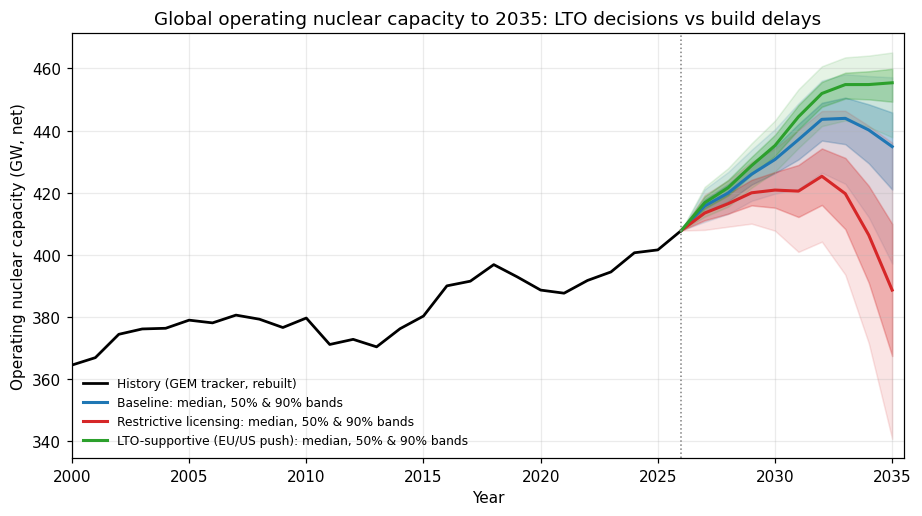

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(series["year"], series["value"], color="black", lw=1.8, label="History (GEM tracker, rebuilt)")

colors = {"Baseline": "tab:blue", "Restrictive licensing": "tab:red", "LTO-supportive (EU/US push)": "tab:green"}
for k, col in colors.items():
    q = np.percentile(scen_paths[k], [5, 25, 50, 75, 95], axis=0)   # simulated year by year, no trend
    ax.fill_between(YEARS, q[0], q[4], color=col, alpha=0.12)
    ax.fill_between(YEARS, q[1], q[3], color=col, alpha=0.28)
    ax.plot(YEARS, q[2], color=col, lw=2, label=f"{k}: median, 50% & 90% bands")

ax.axvline(REF_YEAR, color="grey", ls=":", lw=1)
ax.set(xlabel="Year", ylabel=f"Operating nuclear capacity ({UNIT}, net)",
       title=f"Global operating nuclear capacity to {TARGET}: LTO decisions vs build delays",
       xlim=(2000, TARGET + 0.5))   # zoom: the future is the point
ax.legend(loc="lower left", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("fig_uncertainty.png", dpi=200)
plt.show()

> **Figure choices (F1)**
> - Bands come from the Part C/D simulation **year by year**, not from the trend: the trend failed B2 and cannot see the 2031–35 cohort cliff.
> - 50% band (darker) = "as likely in as out"; 90% band (lighter) = the range we commit to in the paper.
> - Three scenarios shown, not four: delays (+50%) sits between baseline and restrictive and would clutter the plot; it stays in the `scen` table.
> - x-axis from 2000: enough history to see the post-2011 dip and recovery, while giving space to the projection.

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

We project global operating nuclear capacity to 2035 from the GEM Global Nuclear Power Tracker (Aug 2026). Under baseline assumptions (80% of reactors reaching a 50- or 60-year review extended, post-2000 construction lead times), capacity is very likely between 396 and 458 GW (median 435 GW, 90% interval). A linear trend held all 5 held-out years (2022–2026), but a rolling back-test covered only 78% at one year ahead, so trend bands are too narrow and we do not use them. The range is driven by the extension share of the 146 GW ageing cohort: fixing it removes two thirds of the width. The scenario gap (restrictive vs supportive licensing, 67 GW) exceeds the within-scenario width. Limitation: GEM labels Japan's idled reactors as operating, overstating available capacity.

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is* **sequencing**: extension decisions on the 146 GW cohort move 2035 capacity by up to 67 GW vs 15 GW for build delays, so licence certainty for LTO should be secured before committing capital to new builds."